# Section 3 · Notebook 2 — LangGraph + AgentCore Memory (short-term memory)

We give a LangGraph agent **session memory** by using Amazon Bedrock AgentCore Memory as its *checkpointer*. Every step of the conversation is saved automatically, so the agent can pick up where it left off — even from a different process or machine.

| | |
|:--|:--|
| Use case | Multi-step math calculations |
| Framework | LangGraph (via `langchain.agents.create_agent`) |
| Memory | AgentCore Memory — `AgentCoreMemorySaver` checkpointer |
| Complexity | Beginner |

```
 user ──► LangGraph agent ──► Bedrock model
               │  ▲
     save state│  │load state  (every step)
               ▼  │
        AgentCore Memory  (session_id = thread_id, actor_id)
```

**Prerequisites:** AWS credentials, Bedrock access, and IAM permissions for AgentCore Memory (`bedrock-agentcore:CreateMemory`, `CreateEvent`, `ListEvents`, `GetMemory`, `DeleteMemory`, ...).

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


> If pip upgraded any packages, restart the kernel before continuing.

In [2]:
import os

from bedrock_agentcore.memory import MemoryClient
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph_checkpoint_aws import AgentCoreMemorySaver

MODEL_ID = os.getenv("BEDROCK_MODEL_ID", "global.anthropic.claude-haiku-4-5-20251001-v1:0")
REGION = os.getenv("AWS_REGION", os.getenv("AWS_DEFAULT_REGION", "us-east-1"))
print(f"Model: {MODEL_ID} | Region: {REGION}")

Model: global.anthropic.claude-haiku-4-5-20251001-v1:0 | Region: us-east-1


### Create (or reuse) the AgentCore Memory resource

`create_or_get_memory` creates the memory the first time and waits until it is ACTIVE. Running the notebook again simply reuses it. No extraction strategies are needed for short-term memory.

In [3]:
client = MemoryClient(region_name=REGION)
memory = client.create_or_get_memory(
    name="MathLanggraphAgent",
    description="Short-term memory for the LangGraph math agent",
)
memory_id = memory["id"]
print("Memory ID:", memory_id, "| status:", memory.get("status"))

Memory ID: MathLanggraphAgent-ISD1894T3h | status: ACTIVE


### Configure the checkpointer and the model

- `memory_id` — the AgentCore Memory resource that stores checkpoints
- `region_name` — where it lives
- `MODEL_ID` — the Bedrock model that powers the agent

In [4]:
checkpointer = AgentCoreMemorySaver(memory_id, region_name=REGION)
llm = init_chat_model(MODEL_ID, model_provider="bedrock_converse", region_name=REGION)

### Math tools

In [5]:
@tool
def add(a: int, b: int) -> int:
    """Add two integers and return the result."""
    return a + b


@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b


tools = [add, multiply]

### Build the agent with the AgentCore Memory checkpointer

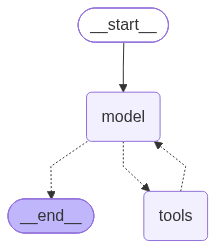

In [6]:
graph = create_agent(
    model=llm,
    tools=tools,
    system_prompt="You are a helpful assistant. Use the tools for every calculation.",
    checkpointer=checkpointer,
)
graph

### Run it

The checkpointer needs two IDs in the run config:
- `thread_id` → AgentCore **session_id** (one conversation)
- `actor_id` → AgentCore **actor_id** (the user or agent)

In [7]:
config = {
    "configurable": {
        "thread_id": "session-1",  # REQUIRED: maps to AgentCore session_id
        "actor_id": "react-agent-1",  # REQUIRED: maps to AgentCore actor_id
    }
}

inputs = {"messages": [{"role": "user", "content": "What is 1337 times 515321? Then add 412 and return the value to me."}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content=[{'type': 'text', 'text': "I'll help you calculate that. First, let me multiply 1337 by 515321, then add 412 to the result."}, {'type': 'tool_use', 'name': 'multiply', 'input': {'a': 1337, 'b': 515321}, 'id': 'tooluse_5pNaWf6HuJhRHxGoRSuB6H'}], additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '52882b70-6281-4b49-b252-3258871dea2a', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Wed, 14 Oct 2026 08:25:38 GMT', 'content-type': 'application/json', 'content-length': '537', 'connection': 'keep-alive', 'x-amzn-requestid': '52882b70-6281-4b49-b252-3258871dea2a'}, 'RetryAttempts': 0}, 'stopReason': 'tool_use', 'metrics': {'latencyMs': [1176]}, 'model_provider': 'bedrock_converse', 'model_name': 'global.anthropic.claude-haiku-4-5-20251001-v1:0'}, id='lc_run--01a13984-56bd-78b1-9626-1c1fc1b011b7-0', tool_calls=[{'name': 'multiply', 'args': {'a': 1337, 'b': 515321}, 'id': 'tooluse_5pNaWf6HuJhRHxGoRSuB6H', 'type': 'tool_call'}], 

### Inspect the saved state

In [8]:
for message in graph.get_state(config).values.get("messages"):
    print(f"{message.type}: {message.text}")
    print("=" * 40)

human: What is 1337 times 515321? Then add 412 and return the value to me.
ai: I'll help you calculate that. First, let me multiply 1337 by 515321, then add 412 to the result.
tool: 688984177
ai: Now let me add 412 to that result:
tool: 688984589
ai: The answer is **688,984,589**.

To break it down:
- 1337 × 515321 = 688,984,177
- 688,984,177 + 412 = **688,984,589**


### Checkpoint history (most recent first)

In [9]:
for checkpoint in graph.get_state_history(config):
    print(
        f"Checkpoint {checkpoint.config['configurable']['checkpoint_id']} "
        f"— messages in state: {len(checkpoint.values.get('messages', []))}"
    )

Adding placeholder ToolMessage for orphaned tool_call 'add' (id: tooluse_AiWiGPokGBAd8kyKFJ1UR5) during checkpoint load
Adding placeholder ToolMessage for orphaned tool_call 'multiply' (id: tooluse_5pNaWf6HuJhRHxGoRSuB6H) during checkpoint load


Checkpoint 1f1c7a8d-7adb-6110-8005-b3747406e3b7 — messages in state: 6
Checkpoint 1f1c7a8d-6ed0-6b04-8004-40bdae97a04f — messages in state: 5
Checkpoint 1f1c7a8d-6ec5-6952-8003-db5cae444b5b — messages in state: 5
Checkpoint 1f1c7a8d-61e4-6cd8-8002-ba2fcc4f697c — messages in state: 3
Checkpoint 1f1c7a8d-61da-6c60-8001-83e405c27bc8 — messages in state: 3
Checkpoint 1f1c7a8d-4fd3-6256-8000-71df139fa372 — messages in state: 1
Checkpoint 1f1c7a8d-4fbd-680c-bfff-0d7ddf07660e — messages in state: 0


### Memory persistence — continue the same session

In [10]:
inputs = {"messages": [{"role": "user", "content": "What were the first calculations I asked you to do?"}]}

for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content='The first calculations you asked me to do were:\n\n1. **Multiply 1337 by 515321** (which resulted in 688,984,177)\n2. **Add 412 to that result** (which resulted in 688,984,589)', additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': 'c07cf507-c3dc-4204-8e99-5ed765254cf6', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Wed, 14 Oct 2026 08:25:44 GMT', 'content-type': 'application/json', 'content-length': '491', 'connection': 'keep-alive', 'x-amzn-requestid': 'c07cf507-c3dc-4204-8e99-5ed765254cf6'}, 'RetryAttempts': 0}, 'stopReason': 'end_turn', 'metrics': {'latencyMs': [993]}, 'model_provider': 'bedrock_converse', 'model_name': 'global.anthropic.claude-haiku-4-5-20251001-v1:0'}, id='lc_run--01a13984-6ed6-7083-907f-96de004833e4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 958, 'output_tokens': 62, 'total_tokens': 1020, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}})]}}


### Session isolation — a new session starts empty

In [11]:
config = {
    "configurable": {
        "thread_id": "session-2",  # new session
        "actor_id": "react-agent-1",  # same actor
    }
}

inputs = {"messages": [{"role": "user", "content": "What values did I ask you to multiply and add?"}]}
for chunk in graph.stream(inputs, stream_mode="updates", config=config):
    print(chunk)

{'model': {'messages': [AIMessage(content="I don't have any record of you asking me to multiply or add specific values. This appears to be the start of our conversation, so you haven't provided me with any numbers to work with yet.\n\nIf you'd like me to multiply or add some numbers, please provide them and I'll be happy to help!", additional_kwargs={}, response_metadata={'ResponseMetadata': {'RequestId': '881089ce-45cf-4721-85f6-60079fdadb45', 'HTTPStatusCode': 200, 'HTTPHeaders': {'date': 'Wed, 14 Oct 2026 08:25:46 GMT', 'content-type': 'application/json', 'content-length': '603', 'connection': 'keep-alive', 'x-amzn-requestid': '881089ce-45cf-4721-85f6-60079fdadb45'}, 'RetryAttempts': 0}, 'stopReason': 'end_turn', 'metrics': {'latencyMs': [1496]}, 'model_provider': 'bedrock_converse', 'model_name': 'global.anthropic.claude-haiku-4-5-20251001-v1:0'}, id='lc_run--01a13984-7639-7c60-b36d-b231febed5f5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 661, 'output_

## Summary

1. Created an AgentCore Memory resource
2. Used `AgentCoreMemorySaver` as the LangGraph checkpointer
3. Saw state persist across turns in the same session
4. Saw a new session start with a clean slate

### Clean up

In [12]:
client.delete_memory_and_wait(memory_id=memory_id, max_wait=300, poll_interval=10)
print("Deleted memory", memory_id)

Deleted memory MathLanggraphAgent-ISD1894T3h
